# Detecting AI-Generated Images Under Generator Shift

Does a detector trained on real photos and Stable Diffusion 1.5 fakes still work on Midjourney fakes it has never seen? This notebook compares a CNN, a ResNet and a diffusion reconstruction-error detector. The write-up is in `report/`.

## 1. Loading the dataset

**Dataset:** Tiny-GenImage (Hugging Face), real photographs and AI-generated images from several generators.

In [11]:
from datasets import load_dataset

# Streamed rather than downloaded: the full dataset is ~8 GB.
ds = load_dataset("TheKernel01/Tiny-GenImage", split="train", streaming=True)

print(ds.features)

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'ADM', 'BigGAN', 'GLIDE', 'Midjourney', 'SD14', 'SD15', 'VQDM', 'Wukong'])}


## 2. Exploring the data

In [12]:
import pandas as pd

# Metadata only (no images) for the first 2,000 rows.
meta = ds.select_columns(["label", "generator"])
df = pd.DataFrame(list(meta.take(2000)))

df["label_name"] = df["label"].map(ds.features["label"].int2str)
df["generator_name"] = df["generator"].map(ds.features["generator"].int2str)

df.shape

(2000, 4)

In [3]:
df.head()

,label,generator,label_name,generator_name
0,0,0,real,Real
1,1,1,fake,ADM
2,0,0,real,Real
3,1,2,fake,BigGAN
4,0,0,real,Real


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   label           2000 non-null   int64
 1   generator       2000 non-null   int64
 2   label_name      2000 non-null   str  
 3   generator_name  2000 non-null   str  
dtypes: int64(2), str(2)
memory usage: 79.6 KB


In [5]:
print(df["label_name"].value_counts())
print(df["generator_name"].value_counts())

label_name
real    1000
fake    1000
Name: count, dtype: int64
generator_name
Real          1000
ADM            143
BigGAN         143
GLIDE          143
Midjourney     143
SD15           143
VQDM           143
Wukong         142
Name: count, dtype: int64


## 3. Building the image subset

In [6]:
import numpy as np

want = {"Real": 525, "SD15": 375, "Midjourney": 150}
got = {"Real": [], "SD15": [], "Midjourney": []}

names = ds.features["generator"].names

for row in ds:
    gen = names[row["generator"]]
    if gen not in got or len(got[gen]) >= want[gen]:
        continue
    img = row["image"].convert("RGB").resize((32, 32))
    got[gen].append(np.array(img))
    if all(len(got[k]) >= want[k] for k in want):
        break

for k in got:
    print(k, len(got[k]))

Real 525
SD15 375
Midjourney 150


Matplotlib is building the font cache; this may take a moment.


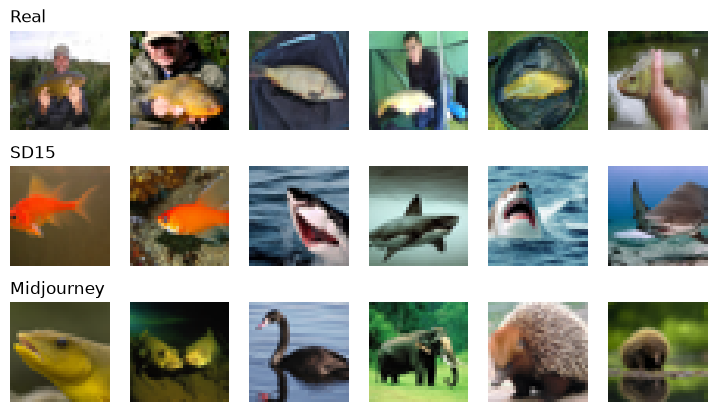

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 6, figsize=(9, 5))

for row_num, name in enumerate(["Real", "SD15", "Midjourney"]):
    for col_num in range(6):
        axes[row_num, col_num].imshow(got[name][col_num])
        axes[row_num, col_num].axis("off")
    axes[row_num, 0].set_title(name, loc="left")

plt.show()

## 4. Data integrity checks

In [8]:
all_imgs = got["Real"] + got["SD15"] + got["Midjourney"]

print("Total images:", len(all_imgs))
print("Shape of one image:", all_imgs[0].shape)
print("Smallest pixel value:", min(img.min() for img in all_imgs))
print("Largest pixel value:", max(img.max() for img in all_imgs))

# Duplicate check: identical images have identical bytes
unique = set(img.tobytes() for img in all_imgs)
print("Unique images:", len(unique))

for img in all_imgs:
    assert img.shape == (32, 32, 3)
print("All shape checks passed")

Total images: 1050
Shape of one image: (32, 32, 3)
Smallest pixel value: 0
Largest pixel value: 255
Unique images: 1050
All shape checks passed


## 5. Preprocessing and data split

In [9]:
# Scale pixel values from 0-255 down to 0-1
real = np.array(got["Real"]).astype("float32") / 255
sd15 = np.array(got["SD15"]).astype("float32") / 255
mj = np.array(got["Midjourney"]).astype("float32") / 255

# Shuffle with a fixed seed so the split is the same every time
rng = np.random.default_rng(42)
real = real[rng.permutation(len(real))]
sd15 = sd15[rng.permutation(len(sd15))]

# 0 = real, 1 = fake
X_train = np.concatenate([real[:225], sd15[:225]])
y_train = np.array([0] * 225 + [1] * 225)

X_val = np.concatenate([real[225:300], sd15[225:300]])
y_val = np.array([0] * 75 + [1] * 75)

X_test = np.concatenate([real[300:375], sd15[300:375]])
y_test = np.array([0] * 75 + [1] * 75)

X_gen = np.concatenate([real[375:525], mj])
y_gen = np.array([0] * 150 + [1] * 150)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Cross-generator test:", X_gen.shape, y_gen.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

Train: (450, 32, 32, 3) (450,)
Validation: (150, 32, 32, 3) (150,)
Test: (150, 32, 32, 3) (150,)
Cross-generator test: (300, 32, 32, 3) (300,)
Pixel range: 0.0 to 1.0


In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader

def to_dataset(X, y):
    # (N, 32, 32, 3) -> (N, 3, 32, 32)
    X = torch.from_numpy(X).permute(0, 3, 1, 2)
    y = torch.from_numpy(y).float()
    return TensorDataset(X, y)

train_loader = DataLoader(to_dataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(to_dataset(X_val, y_val), batch_size=32)
test_loader = DataLoader(to_dataset(X_test, y_test), batch_size=32)
gen_loader = DataLoader(to_dataset(X_gen, y_gen), batch_size=32)

images, labels = next(iter(train_loader))
print("Batch of images:", images.shape)
print("Batch of labels:", labels.shape)

Batch of images: torch.Size([32, 3, 32, 32])
Batch of labels: torch.Size([32])


In [13]:
print(df.isna().sum())

for name, X in [("train", X_train), ("val", X_val), ("test", X_test), ("cross-gen", X_gen)]:
    print(name, "NaN:", np.isnan(X).sum(), "Inf:", np.isinf(X).sum())

for name, y in [("train", y_train), ("val", y_val), ("test", y_test), ("cross-gen", y_gen)]:
    print(name, "real:", (y == 0).sum(), "fake:", (y == 1).sum())

splits = {
    "train": set(x.tobytes() for x in X_train),
    "val": set(x.tobytes() for x in X_val),
    "test": set(x.tobytes() for x in X_test),
    "cross-gen": set(x.tobytes() for x in X_gen),
}
names_list = list(splits)
for i in range(len(names_list)):
    for j in range(i + 1, len(names_list)):
        shared = len(splits[names_list[i]] & splits[names_list[j]])
        print(names_list[i], "vs", names_list[j], "shared images:", shared)

label             0
generator         0
label_name        0
generator_name    0
dtype: int64
train NaN: 0 Inf: 0
val NaN: 0 Inf: 0
test NaN: 0 Inf: 0
cross-gen NaN: 0 Inf: 0
train real: 225 fake: 225
val real: 75 fake: 75
test real: 75 fake: 75
cross-gen real: 150 fake: 150
train vs val shared images: 0
train vs test shared images: 0
train vs cross-gen shared images: 0
val vs test shared images: 0
val vs cross-gen shared images: 0
test vs cross-gen shared images: 0


## 6. CNN baseline

In [14]:
import torch.nn as nn

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

cnn = SimpleCNN().to(device)

print("Device:", device)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))
print("Output shape:", cnn(images.to(device)).shape)

Device: mps
Parameters: 89249
Output shape: torch.Size([32])


In [15]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, count = 0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += ((out > 0).float() == y).sum().item()
        count += len(y)
    return total_loss / count, correct / count

def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += ((out > 0).float() == y).sum().item()
            count += len(y)
    return total_loss / count, correct / count

# Sanity check: the untrained model should be close to guessing
val_loss, val_acc = evaluate(cnn, val_loader)
print("Untrained model, validation loss:", round(val_loss, 3))
print("Untrained model, validation accuracy:", round(val_acc, 3))

Untrained model, validation loss: 0.694
Untrained model, validation accuracy: 0.5


In [16]:
import copy

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = 999
best_weights = None
bad_epochs = 0

for epoch in range(1, 31):
    train_loss, train_acc = train_one_epoch(cnn, train_loader)
    val_loss, val_acc = evaluate(cnn, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:2d} | train loss {train_loss:.3f}, acc {train_acc:.3f} | val loss {val_loss:.3f}, acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(cnn.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= 5:
            print("Validation loss stopped improving, stopping early")
            break

cnn.load_state_dict(best_weights)
print("Best validation loss:", round(best_val_loss, 3))

Epoch  1 | train loss 0.699, acc 0.500 | val loss 0.694, acc 0.500
Epoch  2 | train loss 0.694, acc 0.500 | val loss 0.693, acc 0.500
Epoch  3 | train loss 0.692, acc 0.500 | val loss 0.690, acc 0.500
Epoch  4 | train loss 0.684, acc 0.551 | val loss 0.666, acc 0.707
Epoch  5 | train loss 0.633, acc 0.687 | val loss 0.687, acc 0.573
Epoch  6 | train loss 0.586, acc 0.680 | val loss 0.563, acc 0.713
Epoch  7 | train loss 0.513, acc 0.753 | val loss 0.510, acc 0.747
Epoch  8 | train loss 0.491, acc 0.778 | val loss 0.496, acc 0.753
Epoch  9 | train loss 0.468, acc 0.769 | val loss 0.517, acc 0.747
Epoch 10 | train loss 0.451, acc 0.771 | val loss 0.506, acc 0.727
Epoch 11 | train loss 0.447, acc 0.782 | val loss 0.472, acc 0.773
Epoch 12 | train loss 0.422, acc 0.809 | val loss 0.468, acc 0.760
Epoch 13 | train loss 0.404, acc 0.818 | val loss 0.471, acc 0.760
Epoch 14 | train loss 0.387, acc 0.824 | val loss 0.527, acc 0.720
Epoch 15 | train loss 0.437, acc 0.780 | val loss 0.473, acc 0

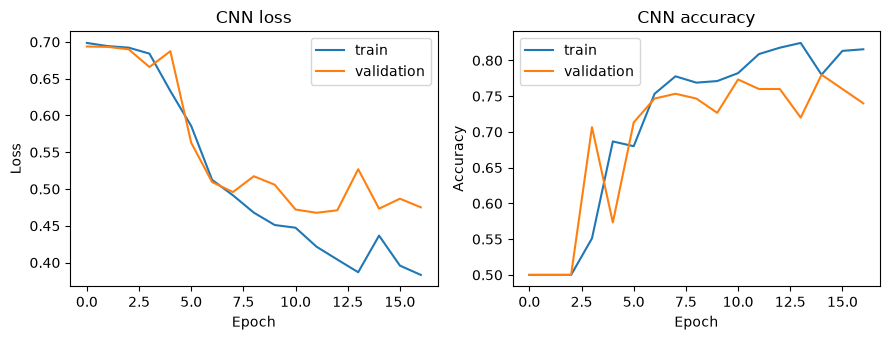

Saved the loss curve and the model weights


In [17]:
import os
import matplotlib.pyplot as plt

os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)

plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("../results/cnn_loss_curve.png", dpi=150)
plt.show()

torch.save(cnn.state_dict(), "../models/cnn_baseline.pt")
print("Saved the loss curve and the model weights")

### CNN evaluation

In [18]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import json

def get_scores(model, loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for X, y in loader:
            out = model(X.to(device))
            scores.extend(torch.sigmoid(out).cpu().numpy())
            labels.extend(y.numpy())
    return np.array(scores), np.array(labels)

cnn_results = {}

for name, loader in [("test_SD15", test_loader), ("cross_gen_Midjourney", gen_loader)]:
    scores, labels = get_scores(cnn, loader)
    preds = (scores > 0.5).astype(int)

    cnn_results[name] = {
        "accuracy": round(float(accuracy_score(labels, preds)), 3),
        "auroc": round(float(roc_auc_score(labels, scores)), 3),
        "f1": round(float(f1_score(labels, preds)), 3),
    }
    print(name, cnn_results[name])
    print(confusion_matrix(labels, preds))
    print()

with open("../results/cnn_metrics.json", "w") as f:
    json.dump(cnn_results, f, indent=2)

test_SD15 {'accuracy': 0.747, 'auroc': 0.84, 'f1': 0.725}
[[62 13]
 [25 50]]

cross_gen_Midjourney {'accuracy': 0.513, 'auroc': 0.492, 'f1': 0.324}
[[119  31]
 [115  35]]



## 7. Diffusion reconstruction-error detector

In [19]:
from diffusers import DDPMPipeline

pipe = DDPMPipeline.from_pretrained("google/ddpm-cifar10-32")
unet = pipe.unet.to(device)
unet.eval()
scheduler = pipe.scheduler

print("Parameters:", sum(p.numel() for p in unet.parameters()))
print("Noise steps in the scheduler:", scheduler.config.num_train_timesteps)

# Quick test: add noise to 8 pictures and let the model predict that noise
x = images[:8].to(device) * 2 - 1
t = torch.full((8,), 100, device=device, dtype=torch.long)
noise = torch.randn_like(x)
noisy = scheduler.add_noise(x, noise, t)

with torch.no_grad():
    pred = unet(noisy, t).sample

print("Prediction shape:", pred.shape)

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
Loading pipeline components...: 100%|██████████| 2/2 [00:00<00:00,  8.75it/s]


Parameters: 35746307
Noise steps in the scheduler: 1000
Prediction shape: torch.Size([8, 3, 32, 32])


### Reconstruction error

In [20]:
def recon_error(X, t_value=100, batch_size=64):
    alpha_bar = scheduler.alphas_cumprod[t_value].item()
    errors = []
    for i in range(0, len(X), batch_size):
        x = torch.from_numpy(X[i:i + batch_size]).permute(0, 3, 1, 2).to(device) * 2 - 1

        # Same noise every run, so the numbers are repeatable
        g = torch.Generator().manual_seed(i)
        noise = torch.randn(x.shape, generator=g).to(device)

        t = torch.full((len(x),), t_value, device=device, dtype=torch.long)
        noisy = scheduler.add_noise(x, noise, t)

        with torch.no_grad():
            pred_noise = unet(noisy, t).sample

        # Rebuild the clean picture from the noisy one
        x_rebuilt = (noisy - (1 - alpha_bar) ** 0.5 * pred_noise) / alpha_bar ** 0.5
        errors.extend(((x_rebuilt - x) ** 2).mean(dim=(1, 2, 3)).cpu().numpy())
    return np.array(errors)

# Quick test on 100 pictures from each group
test_groups = {
    "Real": X_train[:100],
    "SD15": X_train[225:325],
    "Midjourney": X_gen[150:250],
}
for name, X in test_groups.items():
    err = recon_error(X)
    print(name, "| mean error:", round(float(err.mean()), 4), "| std:", round(float(err.std()), 4))

Real | mean error: 0.0109 | std: 0.0046
SD15 | mean error: 0.013 | std: 0.0048
Midjourney | mean error: 0.0107 | std: 0.0044


In [21]:
from sklearn.metrics import roc_auc_score

for t in [25, 50, 100, 200, 400]:
    err = recon_error(X_val, t_value=t)
    auc = roc_auc_score(y_val, err)
    print("t =", t, "| AUROC:", round(auc, 3))

t = 25 | AUROC: 0.488
t = 50 | AUROC: 0.512
t = 100 | AUROC: 0.542
t = 200 | AUROC: 0.6
t = 400 | AUROC: 0.645


In [23]:
for t in [410,420,430,450,480,500,530,550,600, 800, 999]:
    err = recon_error(X_val, t_value=t)
    auc = roc_auc_score(y_val, err)
    print("t =", t, "| AUROC:", round(auc, 3))

t = 410 | AUROC: 0.647
t = 420 | AUROC: 0.646
t = 430 | AUROC: 0.645
t = 450 | AUROC: 0.644
t = 480 | AUROC: 0.638
t = 500 | AUROC: 0.628
t = 530 | AUROC: 0.609
t = 550 | AUROC: 0.594
t = 600 | AUROC: 0.547
t = 800 | AUROC: 0.394
t = 999 | AUROC: 0.433


Chosen noise level t = 410 | validation AUROC: 0.647


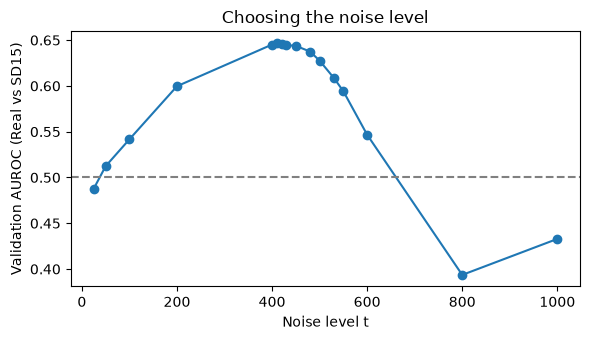

In [24]:
t_values = [25, 50, 100, 200, 400, 410, 420, 430, 450, 480, 500, 530, 550, 600, 800, 999]
aucs = [roc_auc_score(y_val, recon_error(X_val, t_value=t)) for t in t_values]

best_i = int(np.argmax(np.abs(np.array(aucs) - 0.5)))
T_BEST = t_values[best_i]
print("Chosen noise level t =", T_BEST, "| validation AUROC:", round(aucs[best_i], 3))

plt.figure(figsize=(6, 3.5))
plt.plot(t_values, aucs, marker="o")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Noise level t")
plt.ylabel("Validation AUROC (Real vs SD15)")
plt.title("Choosing the noise level")
plt.tight_layout()
plt.savefig("../results/recon_noise_scan.png", dpi=150)
plt.show()

### Extracting reconstruction errors

In [25]:
print("Using t =", T_BEST)

parts = []
for split_name, X, y in [("train", X_train, y_train), ("val", X_val, y_val),
                         ("test", X_test, y_test), ("cross_gen", X_gen, y_gen)]:
    part = pd.DataFrame({
        "split": split_name,
        "label": y,
        "recon_error": recon_error(X, t_value=T_BEST),
    })
    parts.append(part)

errors_df = pd.concat(parts, ignore_index=True)
errors_df.to_csv("../results/recon_errors.csv", index=False)

print(errors_df.shape)
print(errors_df.isna().sum())
print(errors_df.groupby(["split", "label"])["recon_error"].mean().round(4))

Using t = 410
(1050, 3)
split          0
label          0
recon_error    0
dtype: int64
split      label
cross_gen  0        0.0655
           1        0.0676
test       0        0.0611
           1        0.0765
train      0        0.0612
           1        0.0792
val        0        0.0658
           1        0.0792
Name: recon_error, dtype: float32


### Reconstruction-error classifier

In [26]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

train_rows = errors_df[errors_df["split"] == "train"]
val_rows = errors_df[errors_df["split"] == "val"]

recon_clf = make_pipeline(StandardScaler(), LogisticRegression())
recon_clf.fit(train_rows[["recon_error"]], train_rows["label"])

for name, rows in [("train", train_rows), ("validation", val_rows)]:
    scores = recon_clf.predict_proba(rows[["recon_error"]])[:, 1]
    preds = recon_clf.predict(rows[["recon_error"]])
    print(name, "| accuracy:", round(accuracy_score(rows["label"], preds), 3),
          "| AUROC:", round(roc_auc_score(rows["label"], scores), 3))

joblib.dump(recon_clf, "../models/recon_classifier.joblib")
print("Saved the classifier")

train | accuracy: 0.613 | AUROC: 0.669
validation | accuracy: 0.64 | AUROC: 0.647
Saved the classifier


### Reconstruction-error evaluation

In [27]:
recon_results = {}

for name, split in [("test_SD15", "test"), ("cross_gen_Midjourney", "cross_gen")]:
    rows = errors_df[errors_df["split"] == split]
    labels = rows["label"].values
    scores = recon_clf.predict_proba(rows[["recon_error"]])[:, 1]
    preds = recon_clf.predict(rows[["recon_error"]])

    recon_results[name] = {
        "accuracy": round(float(accuracy_score(labels, preds)), 3),
        "auroc": round(float(roc_auc_score(labels, scores)), 3),
        "f1": round(float(f1_score(labels, preds)), 3),
    }
    print(name, recon_results[name])
    print(confusion_matrix(labels, preds))
    print()

with open("../results/recon_metrics.json", "w") as f:
    json.dump(recon_results, f, indent=2)

test_SD15 {'accuracy': 0.6, 'auroc': 0.614, 'f1': 0.559}
[[52 23]
 [37 38]]

cross_gen_Midjourney {'accuracy': 0.507, 'auroc': 0.527, 'f1': 0.452}
[[91 59]
 [89 61]]



## 8. Comparing the two detectors

           model  SD15 accuracy  Midjourney accuracy  SD15 AUROC  Midjourney AUROC  accuracy gap  AUROC gap
CNN (raw pixels)          0.747                0.513       0.840             0.492         0.234      0.348
 Diffusion error          0.600                0.507       0.614             0.527         0.093      0.087


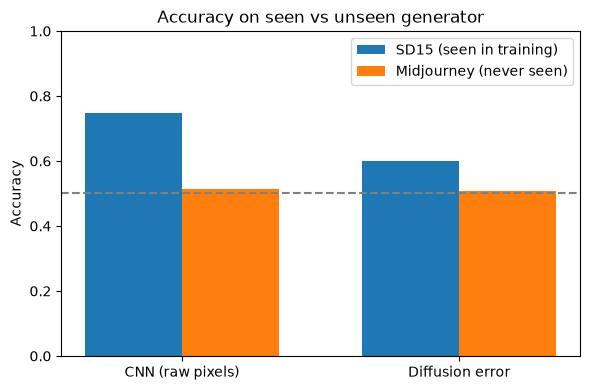

In [28]:
with open("../results/cnn_metrics.json") as f:
    cnn_m = json.load(f)
with open("../results/recon_metrics.json") as f:
    recon_m = json.load(f)

rows = []
for model_name, m in [("CNN (raw pixels)", cnn_m), ("Diffusion error", recon_m)]:
    rows.append({
        "model": model_name,
        "SD15 accuracy": m["test_SD15"]["accuracy"],
        "Midjourney accuracy": m["cross_gen_Midjourney"]["accuracy"],
        "SD15 AUROC": m["test_SD15"]["auroc"],
        "Midjourney AUROC": m["cross_gen_Midjourney"]["auroc"],
    })

comparison = pd.DataFrame(rows)
comparison["accuracy gap"] = (comparison["SD15 accuracy"] - comparison["Midjourney accuracy"]).round(3)
comparison["AUROC gap"] = (comparison["SD15 AUROC"] - comparison["Midjourney AUROC"]).round(3)
comparison.to_csv("../results/comparison_table.csv", index=False)
print(comparison.to_string(index=False))

x = np.arange(len(comparison))
width = 0.35
plt.figure(figsize=(6, 4))
plt.bar(x - width / 2, comparison["SD15 accuracy"], width, label="SD15 (seen in training)")
plt.bar(x + width / 2, comparison["Midjourney accuracy"], width, label="Midjourney (never seen)")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xticks(x, comparison["model"])
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Accuracy on seen vs unseen generator")
plt.legend()
plt.tight_layout()
plt.savefig("../results/comparison_chart.png", dpi=150)
plt.show()

## 9. ResNet

In [29]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.relu = nn.ReLU()
        # 1x1 conv on the skip path when the shape changes
        if stride != 1 or in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1, stride=stride)
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.relu(self.conv1(x))
        out = self.conv2(out)
        return self.relu(out + self.skip(x))


class SmallResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU())
        self.blocks = nn.Sequential(
            ResBlock(16, 16, 1),
            ResBlock(16, 32, 2),
            ResBlock(32, 64, 2),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(0.3), nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.head(self.blocks(self.stem(x))).squeeze(1)


resnet = SmallResNet().to(device)

print("Parameters:", sum(p.numel() for p in resnet.parameters()))
print("Output shape:", resnet(images.to(device)).shape)

Parameters: 77121
Output shape: torch.Size([32])


### ResNet training

In [30]:
torch.manual_seed(42)

# train_one_epoch uses the global optimizer, so point it at the ResNet
optimizer = torch.optim.Adam(resnet.parameters(), lr=0.001)

resnet_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = 999
best_weights = None
bad_epochs = 0

for epoch in range(1, 31):
    train_loss, train_acc = train_one_epoch(resnet, train_loader)
    val_loss, val_acc = evaluate(resnet, val_loader)

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:2d} | train loss {train_loss:.3f}, acc {train_acc:.3f} | val loss {val_loss:.3f}, acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(resnet.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= 5:
            print("Validation loss stopped improving, stopping early")
            break

resnet.load_state_dict(best_weights)
print("Best validation loss:", round(best_val_loss, 3))

Epoch  1 | train loss 0.696, acc 0.500 | val loss 0.691, acc 0.493
Epoch  2 | train loss 0.692, acc 0.529 | val loss 0.685, acc 0.507
Epoch  3 | train loss 0.686, acc 0.522 | val loss 0.667, acc 0.500
Epoch  4 | train loss 0.661, acc 0.609 | val loss 0.622, acc 0.633
Epoch  5 | train loss 0.645, acc 0.604 | val loss 0.593, acc 0.680
Epoch  6 | train loss 0.641, acc 0.633 | val loss 0.615, acc 0.660
Epoch  7 | train loss 0.619, acc 0.638 | val loss 0.630, acc 0.567
Epoch  8 | train loss 0.673, acc 0.596 | val loss 0.651, acc 0.567
Epoch  9 | train loss 0.617, acc 0.662 | val loss 0.590, acc 0.660
Epoch 10 | train loss 0.590, acc 0.671 | val loss 0.564, acc 0.680
Epoch 11 | train loss 0.559, acc 0.709 | val loss 0.572, acc 0.660
Epoch 12 | train loss 0.611, acc 0.656 | val loss 0.560, acc 0.673
Epoch 13 | train loss 0.564, acc 0.722 | val loss 0.569, acc 0.707
Epoch 14 | train loss 0.558, acc 0.707 | val loss 0.544, acc 0.680
Epoch 15 | train loss 0.522, acc 0.760 | val loss 0.531, acc 0

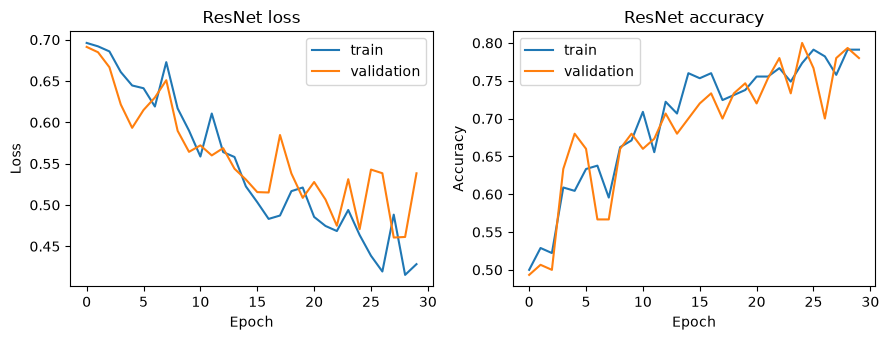

test_SD15 {'accuracy': 0.793, 'auroc': 0.911, 'f1': 0.795}
[[59 16]
 [15 60]]

cross_gen_Midjourney {'accuracy': 0.477, 'auroc': 0.458, 'f1': 0.249}
[[117  33]
 [124  26]]



In [31]:
plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.plot(resnet_history["train_loss"], label="train")
plt.plot(resnet_history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(resnet_history["train_acc"], label="train")
plt.plot(resnet_history["val_acc"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("../results/resnet_loss_curve.png", dpi=150)
plt.show()

torch.save(resnet.state_dict(), "../models/resnet.pt")

resnet_results = {}
for name, loader in [("test_SD15", test_loader), ("cross_gen_Midjourney", gen_loader)]:
    scores, labels = get_scores(resnet, loader)
    preds = (scores > 0.5).astype(int)
    resnet_results[name] = {
        "accuracy": round(float(accuracy_score(labels, preds)), 3),
        "auroc": round(float(roc_auc_score(labels, scores)), 3),
        "f1": round(float(f1_score(labels, preds)), 3),
    }
    print(name, resnet_results[name])
    print(confusion_matrix(labels, preds))
    print()

with open("../results/resnet_metrics.json", "w") as f:
    json.dump(resnet_results, f, indent=2)

### All three detectors

          model  SD15 accuracy  Midjourney accuracy  SD15 AUROC  Midjourney AUROC  accuracy gap  AUROC gap
            CNN          0.747                0.513       0.840             0.492         0.234      0.348
         ResNet          0.793                0.477       0.911             0.458         0.316      0.453
Diffusion error          0.600                0.507       0.614             0.527         0.093      0.087


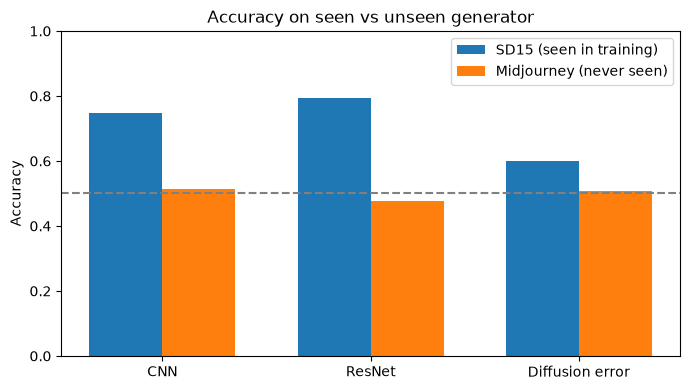

In [32]:
files = {
    "CNN": "../results/cnn_metrics.json",
    "ResNet": "../results/resnet_metrics.json",
    "Diffusion error": "../results/recon_metrics.json",
}

rows = []
for model_name, path in files.items():
    with open(path) as f:
        m = json.load(f)
    rows.append({
        "model": model_name,
        "SD15 accuracy": m["test_SD15"]["accuracy"],
        "Midjourney accuracy": m["cross_gen_Midjourney"]["accuracy"],
        "SD15 AUROC": m["test_SD15"]["auroc"],
        "Midjourney AUROC": m["cross_gen_Midjourney"]["auroc"],
    })

comparison = pd.DataFrame(rows)
comparison["accuracy gap"] = (comparison["SD15 accuracy"] - comparison["Midjourney accuracy"]).round(3)
comparison["AUROC gap"] = (comparison["SD15 AUROC"] - comparison["Midjourney AUROC"]).round(3)
comparison.to_csv("../results/comparison_table.csv", index=False)
print(comparison.to_string(index=False))

x = np.arange(len(comparison))
width = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x - width / 2, comparison["SD15 accuracy"], width, label="SD15 (seen in training)")
plt.bar(x + width / 2, comparison["Midjourney accuracy"], width, label="Midjourney (never seen)")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xticks(x, comparison["model"])
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Accuracy on seen vs unseen generator")
plt.legend()
plt.tight_layout()
plt.savefig("../results/comparison_chart.png", dpi=150)
plt.show()

## 10. Failure analysis

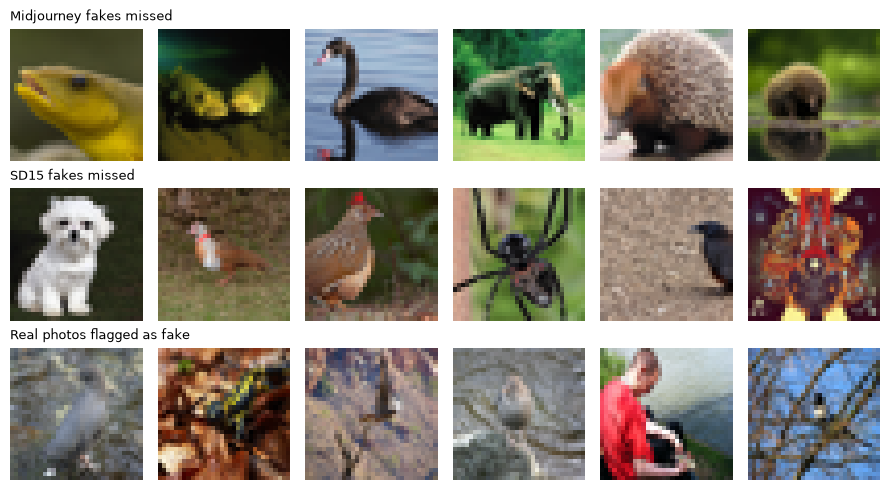

           group   CNN  ResNet
     Real photos 0.251   0.287
      SD15 fakes 0.598   0.630
Midjourney fakes 0.268   0.264


In [33]:
res_gen_scores, _ = get_scores(resnet, gen_loader)
res_test_scores, _ = get_scores(resnet, test_loader)
cnn_gen_scores, _ = get_scores(cnn, gen_loader)
cnn_test_scores, _ = get_scores(cnn, test_loader)

# Pictures the ResNet got wrong
missed_mj = np.where((y_gen == 1) & (res_gen_scores < 0.5))[0]
missed_sd = np.where((y_test == 1) & (res_test_scores < 0.5))[0]
false_alarm = np.where((y_gen == 0) & (res_gen_scores >= 0.5))[0]

groups = [
    ("Midjourney fakes missed", X_gen, missed_mj),
    ("SD15 fakes missed", X_test, missed_sd),
    ("Real photos flagged as fake", X_gen, false_alarm),
]

fig, axes = plt.subplots(3, 6, figsize=(9, 5))
for r, (title, X, idx) in enumerate(groups):
    for c in range(6):
        axes[r, c].axis("off")
        if c < len(idx):
            axes[r, c].imshow(X[idx[c]])
    axes[r, 0].set_title(title, loc="left", fontsize=9)
plt.tight_layout()
plt.savefig("../results/failure_examples_resnet.png", dpi=150)
plt.show()

# How sure were the models? Average chance of "fake" for each group
summary = pd.DataFrame({
    "group": ["Real photos", "SD15 fakes", "Midjourney fakes"],
    "CNN": [cnn_gen_scores[y_gen == 0].mean(),
            cnn_test_scores[y_test == 1].mean(),
            cnn_gen_scores[y_gen == 1].mean()],
    "ResNet": [res_gen_scores[y_gen == 0].mean(),
               res_test_scores[y_test == 1].mean(),
               res_gen_scores[y_gen == 1].mean()],
}).round(3)

summary.to_csv("../results/failure_summary.csv", index=False)
print(summary.to_string(index=False))

### What the example pictures show

Six pictures per group were inspected, so these are observations, not tested conclusions.

- **Missed Midjourney fakes** look like ordinary animal photos at 32×32. Nothing visible separates them from real photos.
- **Real photos flagged as fake** are mostly blurry, low-contrast or cluttered. The models may treat soft or messy texture as a sign of an AI image.
- **One missed SD15 fake** was an obviously unnatural symmetric pattern, which shows the models are not detecting oddness in the picture itself.

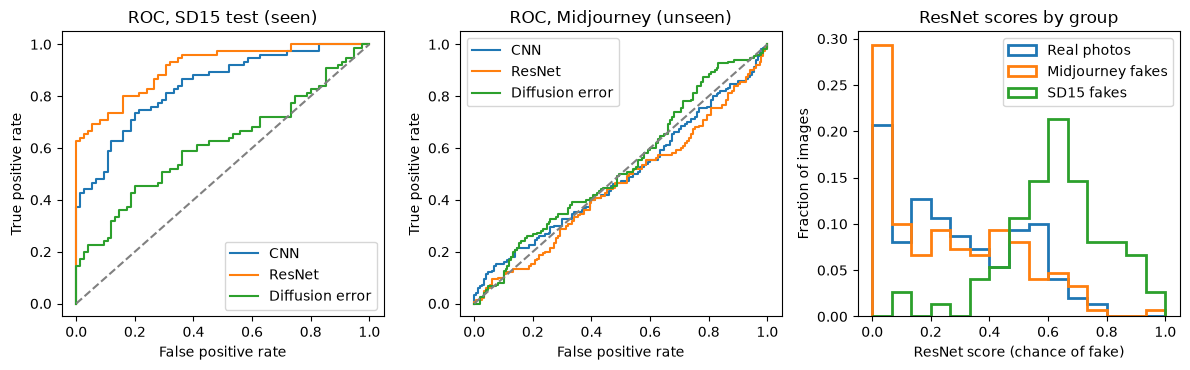

In [35]:
from sklearn.metrics import roc_curve

test_rows = errors_df[errors_df["split"] == "test"]
gen_rows = errors_df[errors_df["split"] == "cross_gen"]
diff_test = recon_clf.predict_proba(test_rows[["recon_error"]])[:, 1]
diff_gen = recon_clf.predict_proba(gen_rows[["recon_error"]])[:, 1]

cnn_test, _ = get_scores(cnn, test_loader)
cnn_gen, _ = get_scores(cnn, gen_loader)
res_test, _ = get_scores(resnet, test_loader)
res_gen, _ = get_scores(resnet, gen_loader)

curves = {
    "CNN": (cnn_test, cnn_gen),
    "ResNet": (res_test, res_gen),
    "Diffusion error": (diff_test, diff_gen),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, idx, title, y in [(axes[0], 0, "ROC, SD15 test (seen)", y_test),
                          (axes[1], 1, "ROC, Midjourney (unseen)", y_gen)]:
    for name, scores in curves.items():
        fpr, tpr, _ = roc_curve(y, scores[idx])
        ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(title)
    ax.legend()

# Same bins for every group, and fractions instead of counts (group sizes differ)
bins = np.linspace(0, 1, 16)
for scores, label in [(res_gen[y_gen == 0], "Real photos"),
                      (res_gen[y_gen == 1], "Midjourney fakes"),
                      (res_test[y_test == 1], "SD15 fakes")]:
    axes[2].hist(scores, bins=bins, weights=np.ones(len(scores)) / len(scores),
                 histtype="step", linewidth=2, label=label)
axes[2].set_xlabel("ResNet score (chance of fake)")
axes[2].set_ylabel("Fraction of images")
axes[2].set_title("ResNet scores by group")
axes[2].legend()

plt.tight_layout()
plt.savefig("../results/roc_and_scores.png", dpi=150)
plt.show()

## 11. Same real photos for both fake groups

In [36]:
from sklearn.metrics import roc_auc_score

# Scores of each model on the test images (no retraining)
cnn_s_test, _ = get_scores(cnn, test_loader)
cnn_s_gen, _ = get_scores(cnn, gen_loader)
res_s_test, _ = get_scores(resnet, test_loader)
res_s_gen, _ = get_scores(resnet, gen_loader)

test_rows = errors_df[errors_df["split"] == "test"]
gen_rows = errors_df[errors_df["split"] == "cross_gen"]
dif_s_test = recon_clf.predict_proba(test_rows[["recon_error"]])[:, 1]
dif_s_gen = recon_clf.predict_proba(gen_rows[["recon_error"]])[:, 1]

all_scores = {
    "CNN": (cnn_s_test, cnn_s_gen),
    "ResNet": (res_s_test, res_s_gen),
    "Diffusion error": (dif_s_test, dif_s_gen),
}

def auc_of(real_sc, fake_sc):
    y = np.r_[np.zeros(len(real_sc)), np.ones(len(fake_sc))]
    return roc_auc_score(y, np.r_[real_sc, fake_sc])

def ci(values):
    lo, hi = np.percentile(values, [2.5, 97.5])
    return f"[{lo:.3f}, {hi:.3f}]"

boot_rng = np.random.default_rng(42)
out_rows = []

for name, (s_test, s_gen) in all_scores.items():
    # the same 225 real photos are used against both fake groups
    r_sc = np.concatenate([s_test[y_test == 0], s_gen[y_gen == 0]])
    sd_sc = s_test[y_test == 1]    # 75 SD15 fakes
    mj_sc = s_gen[y_gen == 1]      # 150 Midjourney fakes

    a_sd = auc_of(r_sc, sd_sc)
    a_mj = auc_of(r_sc, mj_sc)

    sd_boot, mj_boot, gap_boot = [], [], []
    for _ in range(2000):
        r_b = boot_rng.choice(r_sc, len(r_sc))
        x_sd = auc_of(r_b, boot_rng.choice(sd_sc, len(sd_sc)))
        x_mj = auc_of(r_b, boot_rng.choice(mj_sc, len(mj_sc)))
        sd_boot.append(x_sd)
        mj_boot.append(x_mj)
        gap_boot.append(x_sd - x_mj)

    # balanced accuracy at the 0.5 cutoff (real photos correct + fakes correct, averaged)
    real_ok = (r_sc < 0.5).mean()
    bal_sd = (real_ok + (sd_sc >= 0.5).mean()) / 2
    bal_mj = (real_ok + (mj_sc >= 0.5).mean()) / 2

    out_rows.append({
        "model": name,
        "SD15 AUROC": round(a_sd, 3), "SD15 95% CI": ci(sd_boot),
        "Midjourney AUROC": round(a_mj, 3), "Midjourney 95% CI": ci(mj_boot),
        "AUROC gap": round(a_sd - a_mj, 3), "gap 95% CI": ci(gap_boot),
        "SD15 bal. acc": round(bal_sd, 3), "Midjourney bal. acc": round(bal_mj, 3),
    })

common = pd.DataFrame(out_rows)
common.to_csv("../results/common_real_comparison.csv", index=False)
print(common.to_string(index=False))

          model  SD15 AUROC    SD15 95% CI  Midjourney AUROC Midjourney 95% CI  AUROC gap      gap 95% CI  SD15 bal. acc  Midjourney bal. acc
            CNN       0.830 [0.774, 0.881]             0.489    [0.429, 0.554]      0.341  [0.266, 0.415]          0.736                0.519
         ResNet       0.895 [0.852, 0.933]             0.465    [0.404, 0.523]      0.430  [0.367, 0.497]          0.791                0.478
Diffusion error       0.590 [0.512, 0.666]             0.545    [0.487, 0.601]      0.045 [-0.040, 0.132]          0.571                0.521


## 12. Final test on five untouched generators

In [37]:
new_gens = ["ADM", "BigGAN", "GLIDE", "VQDM", "Wukong"]
got_new = {g: [] for g in new_gens}
names = ds.features["generator"].names

for row in ds:
    gen = names[row["generator"]]
    if gen not in got_new or len(got_new[gen]) >= 150:
        continue
    img = row["image"].convert("RGB").resize((32, 32))
    got_new[gen].append(np.array(img).astype("float32") / 255)
    if all(len(v) >= 150 for v in got_new.values()):
        break

for g in new_gens:
    print(g, len(got_new[g]))

ADM 150
BigGAN 150
GLIDE 150
VQDM 150
Wukong 150


In [38]:
from sklearn.metrics import roc_auc_score

real225 = np.concatenate([X_test[y_test == 0], X_gen[y_gen == 0]])

def net_scores(model, X):
    loader = DataLoader(to_dataset(X, np.zeros(len(X), dtype="float32")), batch_size=32)
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.extend(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.array(out)

def diff_scores(X):
    err = recon_error(X, t_value=T_BEST)
    return recon_clf.predict_proba(pd.DataFrame({"recon_error": err}))[:, 1]

scorers = {
    "CNN": lambda X: net_scores(cnn, X),
    "ResNet": lambda X: net_scores(resnet, X),
    "Diffusion error": diff_scores,
}

def auc_of(real_sc, fake_sc):
    y = np.r_[np.zeros(len(real_sc)), np.ones(len(fake_sc))]
    return roc_auc_score(y, np.r_[real_sc, fake_sc])

rng2 = np.random.default_rng(42)
rows = []
for model_name, scorer in scorers.items():
    real_sc = scorer(real225)
    for g in new_gens:
        fake_sc = scorer(np.array(got_new[g]))
        boots = []
        for _ in range(2000):
            r_b = rng2.choice(real_sc, len(real_sc))
            f_b = rng2.choice(fake_sc, len(fake_sc))
            boots.append(auc_of(r_b, f_b))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append({
            "model": model_name,
            "generator": g,
            "AUROC": round(auc_of(real_sc, fake_sc), 3),
            "95% CI": f"[{lo:.3f}, {hi:.3f}]",
            "fakes called fake": round(float((fake_sc >= 0.5).mean()), 3),
            "real called fake": round(float((real_sc >= 0.5).mean()), 3),
        })

final_test = pd.DataFrame(rows)
final_test.to_csv("../results/untouched_generators.csv", index=False)
print(final_test.to_string(index=False))

          model generator  AUROC         95% CI  fakes called fake  real called fake
            CNN       ADM  0.572 [0.511, 0.628]              0.220             0.196
            CNN    BigGAN  0.562 [0.502, 0.621]              0.207             0.196
            CNN     GLIDE  0.595 [0.537, 0.655]              0.333             0.196
            CNN      VQDM  0.483 [0.425, 0.544]              0.113             0.196
            CNN    Wukong  0.838 [0.798, 0.879]              0.647             0.196
         ResNet       ADM  0.522 [0.465, 0.579]              0.213             0.218
         ResNet    BigGAN  0.550 [0.488, 0.610]              0.327             0.218
         ResNet     GLIDE  0.558 [0.497, 0.618]              0.273             0.218
         ResNet      VQDM  0.477 [0.415, 0.541]              0.207             0.218
         ResNet    Wukong  0.876 [0.839, 0.908]              0.747             0.218
Diffusion error       ADM  0.439 [0.380, 0.496]              0.28

### What the untouched generators show

The models and settings were frozen before this test, and all five generators are reported.

- **Only Wukong is detected well.** The CNN (AUROC 0.838) and the ResNet (0.876) separate Wukong fakes from real photos clearly. On ADM, BigGAN, GLIDE and VQDM they are at or only slightly above chance (AUROC 0.477 to 0.595).
- **The diffusion detector's clue changes direction.** On BigGAN (0.277) and VQDM (0.186) its AUROC is far below 0.5, and on ADM (0.439) it is slightly below. These fakes have a lower reconstruction error than real photos, the opposite of SD15. On GLIDE (0.630) and Wukong (0.746) the direction matches SD15. A detector trained on SD15 therefore gets some generators backwards.
- **Caveats.** There are 150 fakes per generator, taken from the first matching rows of the stream. The generators' images have different native sizes, so shrinking to 32x32 changes them by different amounts, and we did not test whether this explains the pattern. Fifteen intervals were computed, so one or two may differ from chance by luck.